# Module 4 – Pipeline, baselines and evaluation

Goal: a first version that runs end to end.
1. Assemble the target and the features (Modules 2 and 3), for each T = 0, 7, 30, 90.
2. Build a scikit-learn pipeline (imputation + scaling **inside** the pipeline, fitted on the train set only).
3. Compare two baselines on the **validation** set: `DummyClassifier` and logistic regression.

**The test set is never used here.** It will be used only once, at the very end, for the final model.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, confusion_matrix)
from config import *

target = pd.read_parquet(PROC_DIR / "target.parquet")           # Module 2: target and split
static = pd.read_parquet(PROC_DIR / "features_static.parquet")  # Module 3: features known at release
print("Games:", len(target), "| Static features:", static.shape)

Games: 10000 | Static features: (10000, 217)


## 1. Target and split (Module 2)

The target and the split come from `target.parquet` (Module 2):
- `success` = top 20% for the number of reviews in the first year (threshold computed **on the train set only**) **and** at least 80% positive reviews;
- `split`: split by release date, oldest 70% in train, 15% in validation, 15% in test, with no release day shared between two splits.

Module 3 uses the same split: the tags kept are chosen on this same train set.

In [2]:
target.groupby("split")["success"].agg(n_games="size", n_successes="sum", rate="mean").loc[["train", "val", "test"]]

,n_games,n_successes,rate
split,,,
train,7007,924,0.131868
val,1499,235,0.156771
test,1494,222,0.148594


Successes are **rare** (about 1 game out of 7): accuracy makes no sense here. A model that always answers "not a success" would get about 85% accuracy in validation without learning anything. The **PR-AUC** is therefore the main metric.

## 2. One dataset per value of T

- T = 0: static features alone.
- T = 7, 30, 90: static features + early signals from `features_T{T}.parquet`.

`desc_length` and `n_reviews` are very skewed (Module 3): they are log-transformed. This is a row-by-row transformation that learns nothing from the data, so there is no leakage risk. It can be done before the split.

In [3]:
def make_dataset(T):
    df = target[["app_id", "split", "success"]].merge(static, on="app_id")
    if T > 0:
        df = df.merge(pd.read_parquet(PROC_DIR / f"features_T{T}.parquet"), on="app_id")
        df["n_reviews"] = np.log1p(df["n_reviews"])
    df["desc_length"] = np.log1p(df["desc_length"])
    return df

make_dataset(30).shape

(10000, 222)

## 3. Pipeline

- Numerical features (`NUM_COLS`): missing values replaced by the **median**, then **scaling** (mean 0, standard deviation 1).
- Release month and weekday (`CAT_COLS`): these are **categories**, not quantities. December (12) is not "12 times" January (1), and for a logistic regression, a linear effect of the month makes no sense. `OneHotEncoder` creates one 0/1 column per month and per day.
- The other columns are already 0/1 (platforms, genres, tags, `in_fronkon`, `has_reviews`): they pass through unchanged (`remainder="passthrough"`).

The median and the scaling are **computed during `fit`, so on the train set only**, then applied to the validation set. Computing them on all the data would leak information from the validation set into training: this is the mistake that caps the grade at 10/20.

In [4]:
NUM_COLS = ["log_price", "required_age", "n_languages", "desc_length", "n_reviews", "pos_ratio"]
CAT_COLS = ["release_month", "release_weekday"]

def make_model(clf, num_cols):
    preprocess = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
        (OneHotEncoder(handle_unknown="ignore"), CAT_COLS),  # one 0/1 column per month and per day
        remainder="passthrough",  # 0/1 columns: unchanged
    )
    return make_pipeline(preprocess, clf)

## 4. Baselines and metrics on the validation set

- `DummyClassifier(strategy="most_frequent")`: always answers "not a success". This is the floor to beat.
- `LogisticRegression(class_weight="balanced")`: gives more weight to the successes, which are rare, so that the model does not ignore them.

Metrics, computed on the **probabilities** (`predict_proba`) for the PR-AUC and the ROC-AUC, and on the predicted classes (threshold 0.5) for F1, precision and recall:
- **PR-AUC (main)**: quality of the ranking of the successes. A random model gets the share of successes;
- ROC-AUC: 0.5 = random, 1 = perfect;
- precision: among the games predicted "success", the share of true successes; recall: among the true successes, the share found.

In [5]:
def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]  # probability of being a success
    pred = proba >= 0.5
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "F1": f1_score(y, pred, zero_division=0),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
    }

results = []
logreg_models = {}  # logistic regression trained for each T (to read its coefficients)
for T in T_VALUES:
    df = make_dataset(T)
    train, val = df[df["split"] == "train"], df[df["split"] == "val"]  # the test set is not used
    X_train, y_train = train.drop(columns=["app_id", "split", "success"]).astype(float), train["success"]
    X_val, y_val = val.drop(columns=["app_id", "split", "success"]).astype(float), val["success"]
    num_cols = [c for c in NUM_COLS if c in X_train.columns]  # n_reviews and pos_ratio only if T > 0

    for name, clf in [("Dummy", DummyClassifier(strategy="most_frequent")),
                      ("LogReg", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))]:
        model = make_model(clf, num_cols).fit(X_train, y_train)
        results.append({"model": name, "T": T, **evaluate(model, X_val, y_val)})
    logreg_models[T] = model  # the last model of the loop is the logistic regression

    print(f"T = {T:>2} | LogReg confusion matrix (rows = true, columns = predicted):")
    print(confusion_matrix(y_val, model.predict(X_val)))

results = pd.DataFrame(results)
print("PR-AUC of a random model (share of successes in validation):", round(y_val.mean(), 3))
results.round(3)

T =  0 | LogReg confusion matrix (rows = true, columns = predicted):
[[932 332]
 [ 91 144]]


T =  7 | LogReg confusion matrix (rows = true, columns = predicted):
[[1079  185]
 [  46  189]]


T = 30 | LogReg confusion matrix (rows = true, columns = predicted):
[[1097  167]
 [  33  202]]


T = 90 | LogReg confusion matrix (rows = true, columns = predicted):
[[1117  147]
 [  27  208]]
PR-AUC of a random model (share of successes in validation): 0.157


,model,T,PR-AUC,ROC-AUC,F1,precision,recall
0,Dummy,0,0.157,0.500,0.000,0.000,0.000
1,LogReg,0,0.407,0.765,0.405,0.303,0.613
2,Dummy,7,0.157,0.500,0.000,0.000,0.000
3,LogReg,7,0.743,0.919,0.621,0.505,0.804
4,Dummy,30,0.157,0.500,0.000,0.000,0.000
5,LogReg,30,0.810,0.943,0.669,0.547,0.860
6,Dummy,90,0.157,0.500,0.000,0.000,0.000
7,LogReg,90,0.850,0.959,0.705,0.586,0.885


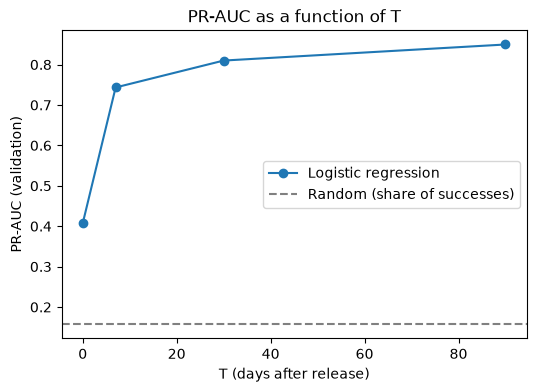

In [6]:
results.to_csv(ROOT / "report" / "results.csv", index=False)

logreg = results[results["model"] == "LogReg"]
plt.figure(figsize=(6, 4))
plt.plot(logreg["T"], logreg["PR-AUC"], marker="o", label="Logistic regression")
plt.axhline(y_val.mean(), color="gray", linestyle="--", label="Random (share of successes)")
plt.xlabel("T (days after release)")
plt.ylabel("PR-AUC (validation)")
plt.title("PR-AUC as a function of T")
plt.legend()
plt.show()

**Reading:**
- **The Dummy has a PR-AUC of 0.157**, exactly the share of successes in validation: this is the random level. Its F1 is 0, because it never predicts a success.
- **At T = 0, the logistic regression is 2.6 times better than random** (PR-AUC 0.407, ROC-AUC 0.77), with only the information known at release. It finds 61% of the successes (144 out of 235), but with many false alarms: 332 games wrongly predicted "success", hence a precision of 30%.
- **The first reviews change everything: from 0.407 to 0.743 as early as T = 7.** After that, the gain slows down: 0.810 at T = 30, 0.850 at T = 90. Most of the information arrives in the first week.
- **At T = 30, 202 successes out of 235 are found** (recall 86%), for 167 false alarms (precision 55%). The 0.5 threshold with `class_weight="balanced"` favours recall.
- **Careful with the interpretation for T > 0:** the target counts the reviews of the first year, and the reviews of the first T days are part of it. Part of the score is therefore mechanical. This is not leakage (these reviews are indeed known at T), but at T = 90, the model has already seen a quarter of the period that defines the target.

**History of the scores at T = 0** (PR-AUC on the validation set):
- 0.442 with the first version;
- 0.435 with the month and weekday one-hot encoded (AI_AUDIT, Flaw 4): no real change;
- 0.411 after removing the categories added after release (Module 3, AI_AUDIT, Flaw 5): part of the score came from information not available at release;
- **0.407 with the Module 2 target and split** (`target.parquet`, AI_AUDIT, Flaw 6): 13 games change split, the difference is negligible.

0.407 is the **honest** reference score. For T ≥ 7, the scores barely move from one version to the next (around 0.74 / 0.81 / 0.85): the first reviews bring much more information than the details of the static features.

These scores do not have a confidence interval yet: the Module 2 bootstrap will tell whether a difference of 0.01 or 0.02 is significant.

## 5. Choice of the baseline model

At this step, we are not looking for the best model: we choose a **reference**, which the next models will have to beat. We first check that we can read what the logistic regression has learned. The numerical features are scaled, so their coefficients are comparable: a positive coefficient increases the probability of success, a negative coefficient decreases it.

In [7]:
# Coefficients of the logistic regression at T = 0 (only the information known at release)
model_T0 = logreg_models[0]
names = model_T0[0].get_feature_names_out()  # step 0 of the pipeline: the preprocessor (names prefixed
                                             # with pipeline__, onehotencoder__ or remainder__)
coefs = pd.Series(model_T0[-1].coef_[0], index=names).sort_values()  # last step: the model

print("8 features that decrease the probability of success the most, then 8 that increase it the most:")
pd.concat([coefs.head(8), coefs.tail(8)]).round(2)

8 features that decrease the probability of success the most, then 8 that increase it the most:


remainder__genre_Violent          -2.13
remainder__win                    -1.27
remainder__cat_MMO                -1.23
remainder__tag_Text-Based         -1.15
remainder__tag_Abstract           -0.97
remainder__tag_Combat             -0.96
remainder__tag_Top-Down Shooter   -0.95
remainder__tag_Sports             -0.93
remainder__tag_Detective           0.87
remainder__genre_Sports            0.89
remainder__tag_Multiplayer         0.89
remainder__cat_Online Co-op        1.04
remainder__tag_Visual Novel        1.08
remainder__tag_Utilities           1.24
remainder__is_free                 1.46
remainder__tag_Hentai              1.58
dtype: float64

**Reading the coefficients (T = 0):**

For a 0/1 feature (tag, genre, platform), the coefficient is the effect of having this tag, **all other features being fixed**. These are associations, not causes.

- **Signals consistent with the target** (many reviews **and** ≥ 80% positive). Niches with a loyal and enthusiastic audience push towards success: `Visual Novel` (33.6% of successes in the train set), `Detective` (34.7%), `Hentai` (56.0%), vs 13.2% on average. Conversely, `genre_Violent` (0 successes out of 74 train games), `MMO` (5.0%) and `Text-Based` (6.6%) push away from it: MMOs get many negative reviews.
- **A leak detected thanks to the coefficients.** In the first version, `cat_Remote Play on Tablet` was among the strongest positive coefficients (+1.17), with 66.7% of successes in the train set. While checking, we found 9 Steam categories added **after** the release (Remote Play, Family Sharing, Steam Trading Cards, accessibility). They were removed in Module 3 (AI_AUDIT, Flaw 5). None of them is left in the top above.
- **Caution with some coefficients**, which do not say the same thing as the raw success rate:
  - `win` (98.4% of the games) has a coefficient of −1.27, although Windows games have more successes (13.4% vs 2.7%). An almost constant feature has an unstable coefficient, which means nothing.
  - `tag_Sports` (−0.93) and `genre_Sports` (+0.89) describe almost the same thing, but have opposite signs. When two features are highly related, the model splits the effect between them arbitrarily: each coefficient cannot be read alone.
  - The largest coefficients concern **rare** tags (70 to 120 games, around the 1% threshold). The model gives them a lot of weight from few examples: the regularisation (`C`) will have to be tuned on the validation set at the next step.
- **No numerical feature in the top 16**: at T = 0, it is mostly the type of game and its tags that matter, more than the price or the number of languages.

### Chosen baseline model: the logistic regression

| Criterion | Why the logistic regression |
|---|---|
| **It clearly beats the floor** | PR-AUC of 0.407 at T = 0 and 0.810 at T = 30, vs 0.157 for the Dummy (random), at every T. The problem can therefore be learned with our features. |
| **It is interpretable** | One coefficient per feature: we can explain what pushes towards success. This is what allowed us to **detect the leak of the categories added after release**. |
| **A single real tuning decision** | The regularisation `C`, left at its default here. It is a simple and reproducible reference (`random_state=SEED`). |
| **It handles the imbalance** | `class_weight="balanced"` gives more weight to the successes (1 game out of 7), without resampling. |
| **It gives probabilities** | `predict_proba` makes it possible to compute the PR-AUC and to choose a decision threshold later, on the validation set. |
| **Fast and seen in class** | It trains in a few seconds on 7,000 games and about 240 features. |

The **Dummy** is not a candidate: it is the **floor**, which shows what a model that learns nothing is worth.

**Known limitations, to address at the next step:**
- the model is linear: it captures neither thresholds ("beyond 50 reviews at T = 7, success is very likely") nor interactions ("Indie tag **and** free"). This is what the next models (random forest, gradient boosting) will have to bring;
- the regularisation `C` is not tuned, hence the large coefficients on rare tags and the unstable signs between related features.

A more complex model will only be chosen if it beats this reference on the **validation** set, by a margin larger than the confidence interval.

**Files produced:** `report/results.csv` (Dummy and logistic regression for T = 0, 7, 30, 90), the reference table for the next steps.